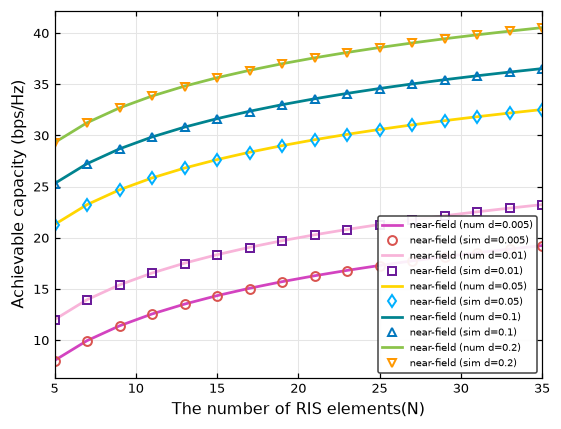

In [1]:
import numpy as np
import matplotlib.pyplot as plt
                                                                           
# BƯỚC 1: KHỞI TẠO CÁC THAM SỐ HỆ THỐNG    
c = 3e8                                          # Vận tốc ánh sáng (m/s)
f2 = 30e9                                        # Tần số sóng mang mmWave trường gần (30 GHz)
Pt = 1e-3 * 10 ** (20 / 10)                      # Công suất phát Pt = 20 dBm = 0.1 W[cite: 7, 9]
d1, d2 = 0.8e3, 5e3                              # Khoảng cách BS-RIS (0.8 km) và RIS-User (5 km)
th_b, ph_b = np.pi / 6, np.pi / 3                # Góc ngẩng và phương vị phía BS 
th_u, ph_u = np.pi / 6, np.pi / 6                # Góc ngẩng và phương vị phía User 
d_list = [0.005, 0.01, 0.05, 0.1, 0.2]           # Danh sách kích thước phần tử d (m)
N_list = np.arange(5, 36, 2)                     # Danh sách số phần tử N (5, 7, ..., 35)

# Tham số anten và tạp âm chuẩn hóa
Gt_dB, Gr_dB = 31.6, 31.6                         # Độ lợi anten BS và User
Gt = 10 ** (Gt_dB / 10)
Gr = 10 ** (Gr_dB / 10)
sigma2 = 1.05e-20                                # Mức công suất tạp âm nhiệt chuẩn hóa băng rộng 30 GHz

# Đại lượng dẫn xuất hình học
lam = c / f2                                     # Bước sóng lambda (0.01 m)
F = lambda th, w=1: np.cos(th) ** w              # Hàm búp sóng đơn vị (Eq. 4) 
Om1 = np.sin(th_b) * np.cos(ph_b)                
Om2 = np.sin(th_u) * np.cos(ph_u)               
F1_F2_max = F(th_b) * F(th_u)                   
                                                                         
# BƯỚC 2: ĐỊNH NGHĨA CÁC HÀM TÍNH TOÁN                                                                              
def T_func(u_a, u_b, om):
    """Hàm phụ trợ tính tích phân giải tích góc theo Eq. (19) & Eq. (20)"""
    T_func = (u_a * u_b) / (om * np.sqrt(om**2 + u_a**2 + u_b**2))
    return np.arctan(T_func)

def C_analytic_nfc(N, d):
    """Hàm tính dung lượng giải tích (Numerical) theo cận trên Hölder (Eq. 20)"""
    pounds1 = (N * d) / (2 * d1)
    pounds2 = (N * d) / (2 * d2)

    U1, U2 = pounds1 - Om1, pounds1 + Om1 
    U3, U4 = pounds1 - np.cos(th_b), pounds1 + np.cos(th_b) 

    V1, V2 = pounds2 - Om2, pounds2 + Om2 
    V3, V4 = pounds2 - np.cos(th_u), pounds2 + np.cos(th_u) 

    sum_T = (T_func(U1, U3, Om1) + T_func(U2, U3, Om1) + 
             T_func(U1, U4, Om1) + T_func(U2, U4, Om1)) 

    sum_S = (T_func(V1, V3, Om2) + T_func(V2, V3, Om2) + 
             T_func(V1, V4, Om2) + T_func(V2, V4, Om2))   

    # Tính SNR cận trên theo Eq. (20) kết hợp hệ số khẩu độ hình học 
    snr_num = (Pt / sigma2) * (Gt * Gr / (16 * np.pi**2)) * F1_F2_max * np.abs(sum_T * sum_S)

    # Dung lượng bán song công 2 chặng: C = log2(1 + SNR) 
    return np.log2(1 + snr_num)  

def C_simulated_nfc(N, d):
    """Hàm tính dung lượng mô phỏng (Simulation) theo mô hình sóng cầu (Eq. 12, 13, 16, 17) """
    idx = np.arange(N) - (N - 1) / 2 
    m, n = np.meshgrid(idx, idx)

    rho1 = d / d1  
    rho2 = d / d2  
    kappa = m**2 + n**2  

    # Khoảng cách hình cầu từ phần tử (m, n) tới BS và User (Eq. 2 & Eq. 3) 
    d1_nm = d1 * np.sqrt(1 - 2*m*rho1*np.sin(th_b)*np.sin(ph_b) - 2*n*rho1*np.cos(th_b) + kappa*(rho1**2))  
    d2_nm = d2 * np.sqrt(1 - 2*m*rho2*np.sin(th_u)*np.sin(ph_u) - 2*n*rho2*np.cos(th_u) + kappa*(rho2**2))  

    # Suy hao đường truyền trường gần từng phần tử (Eq. 12 & Eq. 13) 
    PL1_nm = (4 * np.pi * (d1_nm**3)) / (Gt * F(th_b) * (d**2) * d1 * Om1)  
    PL2_nm = (4 * np.pi * (d2_nm**3)) / (Gr * F(th_u) * (d**2) * d2 * Om2)   

    # Đáp ứng kênh từng phần tử và bù pha tối ưu (Eq. 14, 15, 17) 
    h1 = (1.0 / np.sqrt(PL1_nm)) * np.exp(-1j * 2 * np.pi * f2 * d1_nm / c)  
    h2 = (1.0 / np.sqrt(PL2_nm)) * np.exp(-1j * 2 * np.pi * f2 * d2_nm / c)  
    alpha_nm = 2 * np.pi * f2 * (d1_nm + d2_nm) / c  
    Theta = np.exp(1j * alpha_nm)

    # Tổng hợp kênh cộng cộng pha trên toàn bộ bề mặt mảng N x N 
    h_total = np.sum(h2 * Theta * h1)  
    snr_sim = (Pt / sigma2) * (np.abs(h_total)**2)  

    # Dung lượng bán song công 2 chặng: C = 0.5 * log2(1 + SNR) 
    return np.log2(1 + snr_sim)  
                                                 
# BƯỚC 3: MÔ PHỎNG VÀ VẼ ĐỒ THỊ                                                                               

plot_configs = [
    {"d": 0.005, "line_color": "#d343c0", "marker": "o", "edge_color": "#d9534f"},  
    {"d": 0.010, "line_color": "#f8b4d9", "marker": "s", "edge_color": "#6a1b9a"},  
    {"d": 0.050, "line_color": "#ffd600", "marker": "d", "edge_color": "#00b0ff"},  
    {"d": 0.100, "line_color": "#00838f", "marker": "^", "edge_color": "#0277bd"},  
    {"d": 0.200, "line_color": "#8bc34a", "marker": "v", "edge_color": "#ff9800"}, 
]

# Tạo khung đồ thị kích thước vừa vặn
fig, ax = plt.subplots(figsize=(5.2, 4.0), dpi=110)

for cfg in plot_configs:
    d = cfg["d"]
    Mang_num = []
    Mang_sim = []

    for N in N_list:
        GIA_TRI_num = C_analytic_nfc(N, d) 
        GIA_TRI_sim = C_simulated_nfc(N, d) 

        Mang_num.append(GIA_TRI_num)
        Mang_sim.append(GIA_TRI_sim)

    # 1. Vẽ đường nét liền giải tích cận trên (num)
    ax.plot(N_list, Mang_num, linestyle='-', color=cfg["line_color"], linewidth=1.8, 
            label=f'near-field (num d={d})') 
    
    # 2. Vẽ điểm rời rạc mô phỏng sóng cầu (sim)
    ax.plot(N_list, Mang_sim, linestyle='None', marker=cfg["marker"], markersize=5.8, 
            markerfacecolor='none', markeredgecolor=cfg["edge_color"], markeredgewidth=1.3, 
            label=f'near-field (sim d={d})') 

# Thiết lập hiển thị trục khớp với Fig. 3
ax.set_xlabel('The number of RIS elements(N)', fontsize=10.5) 
ax.set_ylabel('Achievable capacity (bps/Hz)', fontsize=10.5) 
ax.set_xlim(5, 35)

ax.grid(True, linestyle='-', color='#e5e5e5', linewidth=0.7)
ax.legend(fontsize=6.5, loc='lower right', framealpha=0.92, edgecolor='#333333') 
ax.tick_params(direction='in', top=True, right=True, labelsize=8.5)

plt.tight_layout()
plt.show()
